# CDC COVID-19 Case Surveillance: Data Extraction and Exploration

This notebook queries the CDC Socrata dataset `vbim-akqf` using paginated API requests, cleans a bounded extract, checks data quality, and creates descriptive summaries and plots.

**Source:** [CDC dataset and documentation](https://data.cdc.gov/Case-Surveillance/COVID-19-Case-Surveillance-Public-Use-Data/vbim-akqf/about_data) | [Socrata API](https://data.cdc.gov/resource/vbim-akqf.json)

**Important interpretation notes:** CDC discontinued new reporting to this dataset on July 1, 2024. The data are provisional, subject to retrospective changes, have suppressed values, and reflect reporting practices that differ across jurisdictions and time. The public-use dataset has no state or other geographic field. These are case-surveillance records, not population-level rates, causal estimates, or a measure of current COVID-19 activity. A bounded, capped extraction is configured below; do not assume it represents every record in the selected date range.

## 1. Environment Setup and Library Imports

Install any missing packages in your active notebook environment with `%pip install requests pandas numpy matplotlib seaborn`.

In [1]:
import os
import time
from pathlib import Path
from urllib3.util.retry import Retry

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from requests.adapters import HTTPAdapter
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print(f"pandas {pd.__version__}; requests {requests.__version__}")

pandas 3.1.0; requests 2.34.2


## 2. Configure CDC Socrata Endpoint and Query Parameters

The source contains over 100 million records. This starter run requests only January 2024 and stops after 50,000 rows. The selected columns are the available case-level fields; the dataset does **not** contain state or county. You can change the dates or cap, but larger pulls take longer and may be throttled. An optional Socrata app token is read from the `SOCRATA_APP_TOKEN` environment variable.

In [2]:
BASE_URL = "https://data.cdc.gov/resource/vbim-akqf.json"
START_DATE = "2024-01-01T00:00:00.000"
END_DATE = "2024-02-01T00:00:00.000"  # exclusive
PAGE_SIZE = 10_000
MAX_RECORDS = 50_000

SOURCE_COLUMNS = [
    "cdc_case_earliest_dt",
    "cdc_report_dt",
    "onset_dt",
    "current_status",
    "sex",
    "age_group",
    "race_ethnicity_combined",
    "hosp_yn",
    "icu_yn",
    "death_yn",
    "medcond_yn",
]

QUERY_PARAMS = {
    "$select": ",".join(SOURCE_COLUMNS),
    "$where": (
        f"cdc_report_dt >= '{START_DATE}' "
        f"AND cdc_report_dt < '{END_DATE}'"
    ),
    "$order": "cdc_report_dt ASC, cdc_case_earliest_dt ASC, :id ASC",
}

APP_TOKEN = os.getenv("SOCRATA_APP_TOKEN")
REQUEST_HEADERS = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}

print(f"Endpoint: {BASE_URL}")
print(f"Report-date window: {START_DATE} through {END_DATE} (exclusive)")
print(f"Maximum rows for this run: {MAX_RECORDS:,}")

Endpoint: https://data.cdc.gov/resource/vbim-akqf.json
Report-date window: 2024-01-01T00:00:00.000 through 2024-02-01T00:00:00.000 (exclusive)
Maximum rows for this run: 50,000


## 3. Download Data with Pagination

Every request has an explicit limit and offset. Retries cover transient rate-limit and server errors. The loop stops on an empty page or at the configured cap; hitting the cap means the returned data may be incomplete for the selected dates.

In [3]:
def build_session():
    retry = Retry(
        total=5,
        connect=5,
        read=5,
        backoff_factor=0.8,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset({"GET"}),
        respect_retry_after_header=True,
    )
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    session.headers.update(REQUEST_HEADERS)
    return session


def fetch_all_pages(base_url, query_params, page_size=PAGE_SIZE, max_records=MAX_RECORDS):
    """Fetch JSON pages until exhausted or until the safety cap is reached."""
    session = build_session()
    records = []
    offset = 0

    while offset < max_records:
        limit = min(page_size, max_records - offset)
        params = {**query_params, "$limit": limit, "$offset": offset}
        response = session.get(base_url, params=params, timeout=(10, 90))
        try:
            response.raise_for_status()
        except requests.HTTPError as error:
            detail = response.text[:500]
            raise requests.HTTPError(
                f"Socrata request failed ({response.status_code}): {detail}"
            ) from error

        try:
            page = response.json()
        except ValueError as error:
            raise ValueError("The Socrata API returned a non-JSON response.") from error
        if not isinstance(page, list):
            raise ValueError(f"Expected a list of records, received {type(page).__name__}.")
        if not page:
            break

        records.extend(page)
        offset += len(page)
        print(f"Fetched {offset:,} rows (last page: {len(page):,})")
        if len(page) < limit:
            break
        time.sleep(0.1)

    if len(records) >= max_records:
        print("Reached MAX_RECORDS; this may be a partial extract.")
    return records

## 4. Load API Responses into Pandas DataFrames

The API response is held in memory for this bounded run. For large extracts, lower the cap or process pages incrementally to disk instead of accumulating all records.

In [4]:
raw_records = fetch_all_pages(BASE_URL, QUERY_PARAMS)
raw_df = pd.DataFrame.from_records(raw_records, columns=SOURCE_COLUMNS)

print(f"Extract shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
display(raw_df.head())
raw_df.dtypes

Fetched 10,000 rows (last page: 10,000)
Fetched 20,000 rows (last page: 10,000)
Fetched 30,000 rows (last page: 10,000)
Fetched 40,000 rows (last page: 10,000)
Fetched 50,000 rows (last page: 10,000)
Reached MAX_RECORDS; this may be a partial extract.
Extract shape: 50,000 rows x 11 columns


,cdc_case_earliest_dt,cdc_report_dt,onset_dt,current_status,sex,age_group,race_ethnicity_combined,hosp_yn,icu_yn,death_yn,medcond_yn
0,2020-04-24T00:00:00.000,2024-01-01T00:00:00.000,2020-04-24T00:00:00.000,Laboratory-confirmed case,Female,70 - 79 Years,Unknown,Missing,Missing,Missing,Missing
1,2020-07-06T00:00:00.000,2024-01-01T00:00:00.000,2020-07-06T00:00:00.000,Laboratory-confirmed case,Female,40 - 49 Years,Unknown,Missing,Missing,Missing,Missing
2,2020-08-04T00:00:00.000,2024-01-01T00:00:00.000,2020-08-04T00:00:00.000,Laboratory-confirmed case,Female,50 - 59 Years,Unknown,Missing,Missing,Missing,Missing
3,2020-12-13T00:00:00.000,2024-01-01T00:00:00.000,2020-12-13T00:00:00.000,Probable Case,Female,60 - 69 Years,Unknown,Missing,Missing,Missing,Missing
4,2020-12-25T00:00:00.000,2024-01-01T00:00:00.000,2020-12-25T00:00:00.000,Laboratory-confirmed case,Female,Missing,"White, Non-Hispanic",Missing,Missing,Missing,Missing


cdc_case_earliest_dt       str
cdc_report_dt              str
onset_dt                   str
current_status             str
sex                        str
age_group                  str
race_ethnicity_combined    str
hosp_yn                    str
icu_yn                     str
death_yn                   str
medcond_yn                 str
dtype: object

## 5. Clean and Standardize Core Fields

Dates are parsed as datetimes; category values are trimmed and standardized while preserving `Unknown`, `Missing`, and `NA`. Source column names are mapped to readable names, with the original-to-cleaned mapping kept here for traceability.

In [5]:
COLUMN_RENAME = {
    "cdc_case_earliest_dt": "earliest_case_date",
    "cdc_report_dt": "report_date",
    "onset_dt": "onset_date",
    "current_status": "case_status",
    "sex": "sex",
    "age_group": "age_group",
    "race_ethnicity_combined": "race_ethnicity",
    "hosp_yn": "hospitalized",
    "icu_yn": "icu_admission",
    "death_yn": "death",
    "medcond_yn": "underlying_condition",
}
DATE_COLUMNS = ["cdc_case_earliest_dt", "cdc_report_dt", "onset_dt"]
CATEGORY_COLUMNS = [column for column in SOURCE_COLUMNS if column not in DATE_COLUMNS]


def clean_surveillance_data(frame):
    cleaned = frame.copy()
    for column in DATE_COLUMNS:
        cleaned[column] = pd.to_datetime(cleaned[column], errors="coerce")
    for column in CATEGORY_COLUMNS:
        values = cleaned[column].astype("string").str.strip().str.lower()
        cleaned[column] = values.replace(
            {"yes": "Yes", "no": "No", "unknown": "Unknown", "missing": "Missing", "na": "NA"}
        ).str.title().replace({"Na": "NA"})
    return cleaned.rename(columns=COLUMN_RENAME)


clean_df = clean_surveillance_data(raw_df)
display(clean_df.head())
clean_df.dtypes

,earliest_case_date,report_date,onset_date,case_status,sex,age_group,race_ethnicity,hospitalized,icu_admission,death,underlying_condition
0,2020-04-24,2024-01-01,2020-04-24,Laboratory-Confirmed Case,Female,70 - 79 Years,Unknown,Missing,Missing,Missing,Missing
1,2020-07-06,2024-01-01,2020-07-06,Laboratory-Confirmed Case,Female,40 - 49 Years,Unknown,Missing,Missing,Missing,Missing
2,2020-08-04,2024-01-01,2020-08-04,Laboratory-Confirmed Case,Female,50 - 59 Years,Unknown,Missing,Missing,Missing,Missing
3,2020-12-13,2024-01-01,2020-12-13,Probable Case,Female,60 - 69 Years,Unknown,Missing,Missing,Missing,Missing
4,2020-12-25,2024-01-01,2020-12-25,Laboratory-Confirmed Case,Female,Missing,"White, Non-Hispanic",Missing,Missing,Missing,Missing


earliest_case_date      datetime64[us]
report_date             datetime64[us]
onset_date              datetime64[us]
case_status                     string
sex                             string
age_group                       string
race_ethnicity                  string
hospitalized                    string
icu_admission                   string
death                           string
underlying_condition            string
dtype: object

## 6. Validate Data Quality and Missingness

These checks describe the downloaded extract only. A repeated row is flagged for review, not automatically removed: the public dataset does not provide a row identifier, and duplicate-looking records may have meaning in the source.

In [6]:
missing_flags = clean_df.isna().to_numpy()
null_rate_values = (
    np.mean(missing_flags, axis=0)
    if len(clean_df)
    else np.full(len(clean_df.columns), np.nan)
)
null_rates = pd.Series(
    null_rate_values,
    index=clean_df.columns,
    name="null_rate",
).sort_values(ascending=False).to_frame()
duplicate_rows = int(clean_df.duplicated().sum())

binary_fields = ["hospitalized", "icu_admission", "death", "underlying_condition"]
valid_binary_values = {"Yes", "No", "Unknown", "Missing", "NA"}
invalid_categories = {
    column: sorted(clean_df[column].dropna().unique().tolist())
    for column in binary_fields
    if not set(clean_df[column].dropna().unique()).issubset(valid_binary_values)
}

future_dates = {
    column: int((clean_df[column] > pd.Timestamp.now().normalize()).sum())
    for column in ["earliest_case_date", "report_date", "onset_date"]
}

print(f"Exact duplicate rows: {duplicate_rows:,}")
print("Unexpected binary categories:", invalid_categories or "none")
print("Dates after today:", future_dates)
display(null_rates)

Exact duplicate rows: 33,416
Unexpected binary categories: none
Dates after today: {'earliest_case_date': 0, 'report_date': 0, 'onset_date': 0}


,null_rate
onset_date,0.76188
earliest_case_date,0.00000
report_date,0.00000
case_status,0.00000
sex,0.00000
age_group,0.00000
race_ethnicity,0.00000
hospitalized,0.00000
icu_admission,0.00000
death,0.00000


## 7. Create Time-Series Aggregations

Counts below use `report_date`. Daily/weekly case records and reported deaths or hospitalizations are counts in the downloaded extract. A seven-day rolling average smooths the daily record counts; it does not correct for incomplete coverage or reporting delays.

In [7]:
def aggregate_by_date(frame, date_column="report_date"):
    dated = frame.dropna(subset=[date_column]).copy()
    dated["report_day"] = dated[date_column].dt.floor("D")
    daily = dated.groupby("report_day", as_index=False).agg(
        case_records=("report_day", "size"),
        reported_deaths=("death", lambda values: values.eq("Yes").sum()),
        reported_hospitalizations=("hospitalized", lambda values: values.eq("Yes").sum()),
    )
    daily = daily.sort_values("report_day")
    daily["cases_7day_average"] = daily["case_records"].rolling(7, min_periods=1).mean()

    weekly_source = daily.assign(week_start=daily["report_day"].dt.to_period("W-SUN").dt.start_time)
    weekly = weekly_source.groupby("week_start", as_index=False).agg(
        case_records=("case_records", "sum"),
        reported_deaths=("reported_deaths", "sum"),
        reported_hospitalizations=("reported_hospitalizations", "sum"),
    )
    return daily, weekly


daily_summary, weekly_summary = aggregate_by_date(clean_df)
display(daily_summary.head())
display(weekly_summary.head())

,report_day,case_records,reported_deaths,reported_hospitalizations,cases_7day_average
0,2024-01-01,17617,99,885,17617.000000
1,2024-01-02,27895,137,975,22756.000000
2,2024-01-03,4488,51,86,16666.666667


,week_start,case_records,reported_deaths,reported_hospitalizations
0,2024-01-01,50000,287,1946


## 8. Build State-Level Summary Tables

This dataset deliberately contains no state, county, or other geographic field, so state-level summaries cannot be computed here. CDC publishes a separate [public-use dataset with geography](https://data.cdc.gov/Case-Surveillance/COVID-19-Case-Surveillance-Public-Use-Data-with-Ge/n8mc-b4w4). The tables below use available demographic fields instead; comparisons remain descriptive and may be affected by missing or suppressed values.

In [8]:
def summarize_by_group(frame, dimension):
    return (
        frame.groupby(dimension, dropna=False)
        .agg(
            case_records=(dimension, "size"),
            reported_deaths=("death", lambda values: values.eq("Yes").sum()),
            reported_hospitalizations=("hospitalized", lambda values: values.eq("Yes").sum()),
        )
        .sort_values("case_records", ascending=False)
        .reset_index()
    )


demographic_summaries = {
    dimension: summarize_by_group(clean_df, dimension)
    for dimension in ["age_group", "sex", "race_ethnicity"]
}

geographic_columns = [column for column in ["state", "state_name", "res_state", "county"] if column in clean_df]
if geographic_columns:
    print("Geographic columns available:", geographic_columns)
else:
    print("No state/county fields are present; state-level summaries are unavailable in this dataset.")

display(demographic_summaries["age_group"])
display(demographic_summaries["sex"])
display(demographic_summaries["race_ethnicity"].head(15))

No state/county fields are present; state-level summaries are unavailable in this dataset.


,age_group,case_records,reported_deaths,reported_hospitalizations
0,60 - 69 Years,6855,31,316
1,50 - 59 Years,6486,9,173
2,70 - 79 Years,6312,78,477
3,30 - 39 Years,6028,2,90
4,40 - 49 Years,5690,4,83
5,80+ Years,5623,160,651
6,20 - 29 Years,5531,1,57
7,0 - 9 Years,3690,2,67
8,10 - 19 Years,1954,0,22
9,Missing,1831,0,10


,sex,case_records,reported_deaths,reported_hospitalizations
0,Female,29674,131,1002
1,Male,20181,156,942
2,Unknown,110,0,1
3,Missing,35,0,1


,race_ethnicity,case_records,reported_deaths,reported_hospitalizations
0,"White, Non-Hispanic",21106,188,1063
1,Unknown,12984,39,306
2,"Black, Non-Hispanic",5885,18,244
3,Hispanic/Latino,5827,24,219
4,"Asian, Non-Hispanic",1436,7,63
5,"Multiple/Other, Non-Hispanic",1322,9,35
6,Missing,1125,0,5
7,"American Indian/Alaska Native, Non-Hispanic",255,2,11
8,"Native Hawaiian/Other Pacific Islander, Non-Hi...",60,0,0


## 9. Visualize Cases, Deaths, and Hospitalization Signals

Plots show counts from this bounded extract. They are not per-capita rates, estimates of individual risk, or comparable state rankings.

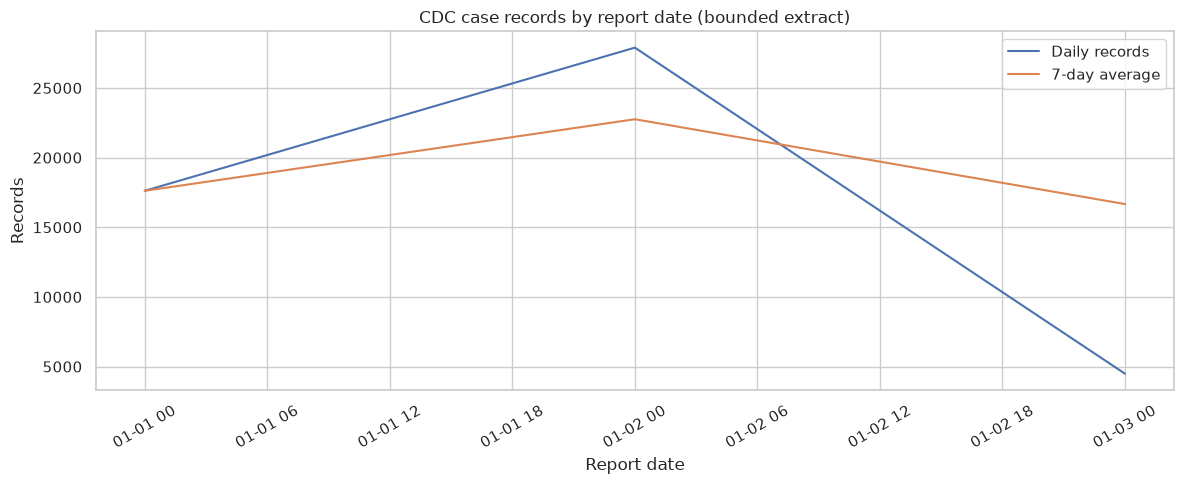

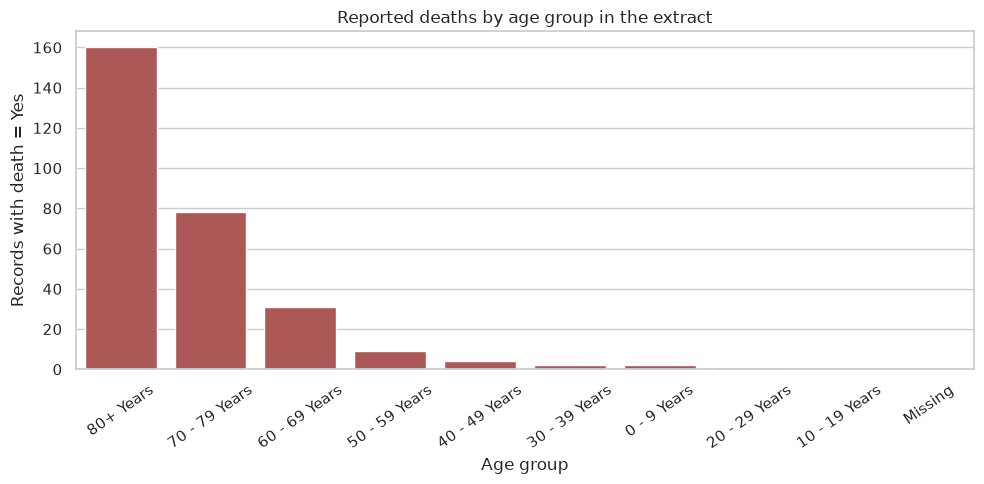

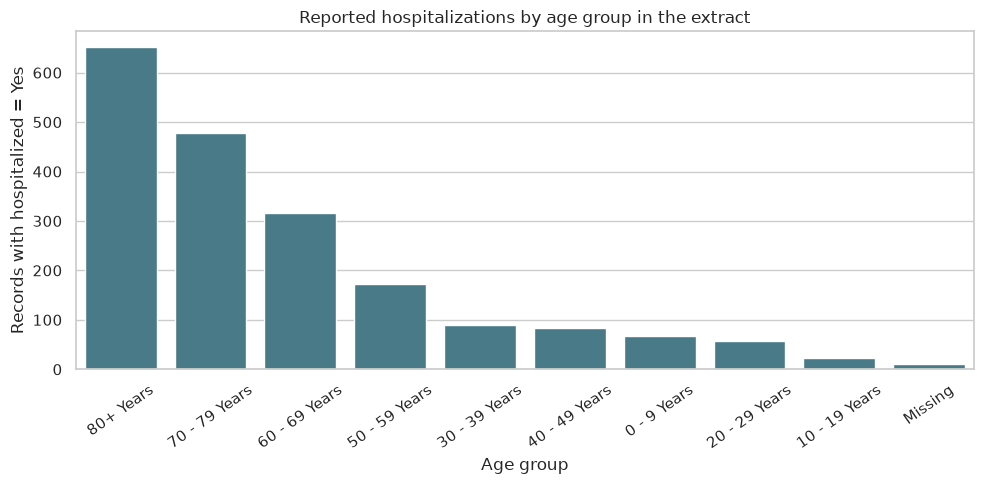

In [9]:
FIGURES_DIR = Path("data") / "cdc_case_surveillance" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not daily_summary.empty:
    figure, axis = plt.subplots(figsize=(12, 5))
    sns.lineplot(data=daily_summary, x="report_day", y="case_records", label="Daily records", ax=axis)
    sns.lineplot(data=daily_summary, x="report_day", y="cases_7day_average", label="7-day average", ax=axis)
    axis.set(title="CDC case records by report date (bounded extract)", xlabel="Report date", ylabel="Records")
    axis.tick_params(axis="x", rotation=30)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / "daily_case_records.png", dpi=150, bbox_inches="tight")
    plt.show()

age_deaths = demographic_summaries["age_group"].sort_values("reported_deaths", ascending=False)
if not age_deaths.empty:
    figure, axis = plt.subplots(figsize=(10, 5))
    sns.barplot(data=age_deaths, x="age_group", y="reported_deaths", color="#b94a48", ax=axis)
    axis.set(title="Reported deaths by age group in the extract", xlabel="Age group", ylabel="Records with death = Yes")
    axis.tick_params(axis="x", rotation=35)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / "deaths_by_age_group.png", dpi=150, bbox_inches="tight")
    plt.show()

age_hospitalizations = demographic_summaries["age_group"].sort_values("reported_hospitalizations", ascending=False)
if not age_hospitalizations.empty:
    figure, axis = plt.subplots(figsize=(10, 5))
    sns.barplot(data=age_hospitalizations, x="age_group", y="reported_hospitalizations", color="#3d8191", ax=axis)
    axis.set(title="Reported hospitalizations by age group in the extract", xlabel="Age group", ylabel="Records with hospitalized = Yes")
    axis.tick_params(axis="x", rotation=35)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / "hospitalizations_by_age_group.png", dpi=150, bbox_inches="tight")
    plt.show()

## 10. Export Cleaned Datasets and Figures

Files are written beneath `data/cdc_case_surveillance/` relative to the notebook's working directory. CSV is used to avoid an extra Parquet dependency. The raw CSV is the bounded API pull, not the complete CDC archive.

In [10]:
OUTPUT_DIR = Path("data") / "cdc_case_surveillance"
FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

raw_df.to_csv(OUTPUT_DIR / "raw_api_extract.csv", index=False)
clean_df.to_csv(OUTPUT_DIR / "cleaned_extract.csv", index=False)
daily_summary.to_csv(OUTPUT_DIR / "daily_summary.csv", index=False)
weekly_summary.to_csv(OUTPUT_DIR / "weekly_summary.csv", index=False)

for dimension, summary in demographic_summaries.items():
    summary.to_csv(OUTPUT_DIR / f"summary_by_{dimension}.csv", index=False)

print(f"Exports saved under: {OUTPUT_DIR.resolve()}")
print("Plot files:", sorted(path.name for path in FIGURES_DIR.glob("*.png")))

Exports saved under: /workspaces/biu_GitHub_Training/Codespace Walkthrough/data/cdc_case_surveillance
Plot files: ['daily_case_records.png', 'deaths_by_age_group.png', 'hospitalizations_by_age_group.png']


## 11. Package Reusable Data-Extraction Functions

`fetch_all_pages`, `clean_surveillance_data`, `aggregate_by_date`, and `summarize_by_group` are defined above so they can be reused independently. This wrapper rebuilds the date-filtered request and returns both the source-shaped and cleaned DataFrames. Adjust `max_records` deliberately; the cap protects against unexpectedly large downloads.

In [11]:
def extract_surveillance(start_date=START_DATE, end_date=END_DATE, max_records=MAX_RECORDS, page_size=PAGE_SIZE):
    """Fetch and clean records by CDC report-date window."""
    query = {
        "$select": ",".join(SOURCE_COLUMNS),
        "$where": f"cdc_report_dt >= '{start_date}' AND cdc_report_dt < '{end_date}'",
        "$order": "cdc_report_dt ASC, cdc_case_earliest_dt ASC, :id ASC",
    }
    records = fetch_all_pages(
        BASE_URL,
        query,
        page_size=page_size,
        max_records=max_records,
    )
    source_frame = pd.DataFrame.from_records(records, columns=SOURCE_COLUMNS)
    return source_frame, clean_surveillance_data(source_frame)


# Example for a different bounded window:
# another_raw, another_clean = extract_surveillance(
#     start_date="2023-12-01T00:00:00.000",
#     end_date="2024-01-01T00:00:00.000",
#     max_records=25_000,
# )